# Retail Price Optimization Capstone

## 02 - Exploratory Data Analysis and Preprocessing

**Student:** Bhupesh Patni  
**Current stage:** Graded Interim Report preparation

### Notebook objective

This notebook prepares the retail pricing dataset for statistical analysis and preliminary demand modelling. It validates the dataset structure, documents preprocessing decisions, engineers research-relevant variables, performs exploratory analysis aligned with the research questions, and exports report-ready tables, figures, and an analysis-ready dataset.

### Analytical goal

The main predictive outcome is sales quantity (`qty`). Unit price (`unit_price`) is treated as a pricing decision variable for studying its association with demand and for later simulated revenue optimization.

### Interpretation boundary

The dataset is observational and aggregated at the product-month level. Relationships are interpreted as associations, not causal effects. Any later price recommendation or revenue uplift will be described as a model-based simulation rather than demonstrated business impact.


## 1. Setup and reproducibility

This section imports the required packages, fixes display settings, creates output folders, and records a random seed for reproducibility.


In [1]:
from pathlib import Path
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

print(f"Python version: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


Python version: 3.13.0
Platform: Windows-11-10.0.26200-SP0
pandas version: 3.0.6
NumPy version: 2.5.4


In [2]:
# Locate the project root regardless of whether the notebook kernel starts
# inside the notebooks folder or at the project root.
current_dir = Path.cwd().resolve()

if current_dir.name.lower() == "notebooks":
    PROJECT_ROOT = current_dir.parent
elif (current_dir / "notebooks").exists() and (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
else:
    possible_roots = [current_dir, *current_dir.parents]
    PROJECT_ROOT = next(
        (
            path for path in possible_roots
            if (path / "notebooks").exists() and (path / "data").exists()
        ),
        current_dir.parent if current_dir.name.lower() == "notebooks" else current_dir,
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

for folder in [PROCESSED_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Current working directory: {current_dir}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Processed data folder: {PROCESSED_DIR}")
print(f"Figures folder: {FIGURES_DIR}")
print(f"Tables folder: {TABLES_DIR}")


Current working directory: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\notebooks
Project root: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone
Processed data folder: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\processed
Figures folder: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\reports\figures
Tables folder: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\reports\tables


## 2. Load the verified dataset

The notebook prefers the cleaned output from Notebook 01 and falls back to the original source file if necessary. The source data are not overwritten.


In [3]:
candidate_paths = [
    RAW_DIR / "retail_price_cleaned.csv",
    RAW_DIR / "retail_price.csv",
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    checked = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(
        "The retail pricing CSV was not found. Checked:\n" + checked
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded: {DATA_PATH}")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.head())


Loaded: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\raw\retail_price_cleaned.csv
Dataset shape: 676 rows x 30 columns


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,2017-05-01,1,45.950,15.100,45.950,39,161,2,350,4.000,57,23,8,1,5,2017,10.267,3800,89.900,3.900,15.012,215.000,4.400,8.760,45.950,4.000,15.100,45.900
1,bed1,bed_bath_table,2017-06-01,3,137.850,12.933,45.950,39,161,2,350,4.000,61,22,8,1,6,2017,6.503,3800,89.900,3.900,14.769,209.000,4.400,21.322,45.950,4.000,12.933,45.950
2,bed1,bed_bath_table,2017-07-01,6,275.700,14.840,45.950,39,161,2,350,4.000,123,21,10,1,7,2017,12.072,3800,89.900,3.900,13.994,205.000,4.400,22.196,45.950,4.000,14.840,45.950
3,bed1,bed_bath_table,2017-08-01,4,183.800,14.287,45.950,39,161,2,350,4.000,90,23,8,1,8,2017,9.294,3800,89.900,3.900,14.657,199.510,4.400,19.413,45.950,4.000,14.287,45.950
4,bed1,bed_bath_table,2017-09-01,2,91.900,15.100,45.950,39,161,2,350,4.000,54,21,9,1,9,2017,5.556,3800,89.900,3.900,18.777,163.399,4.400,24.325,45.950,4.000,15.100,45.950


## 3. Structural validation and observation unit

The expected analytical unit is one product-month record. The checks below verify required columns, dates, products, categories, months, and duplicate product-month combinations.


In [4]:
required_columns = {
    "product_id",
    "product_category_name",
    "month_year",
    "qty",
    "unit_price",
    "freight_price",
    "product_score",
    "comp_1",
    "comp_2",
    "comp_3",
}

missing_required_columns = sorted(required_columns.difference(df.columns))

if missing_required_columns:
    raise KeyError(
        "Required columns are missing: " + ", ".join(missing_required_columns)
    )

# Day-first parsing is used because values follow formats such as 01-05-2017.
# Parse dates safely. Notebook 01 exports the cleaned CSV in ISO YYYY-MM-DD format.
# The fallback handles the original DD-MM-YYYY source file if it is loaded instead.
month_year_text = df["month_year"].astype(str).str.strip()

iso_format_share = month_year_text.str.match(r"^\d{4}-\d{2}-\d{2}$").mean()

if iso_format_share >= 0.95:
    df["month_year"] = pd.to_datetime(
        month_year_text,
        format="%Y-%m-%d",
        errors="coerce",
    )
    detected_date_format = "ISO YYYY-MM-DD"
else:
    df["month_year"] = pd.to_datetime(
        month_year_text,
        dayfirst=True,
        errors="coerce",
    )
    detected_date_format = "day-first source format"

print(f"Detected date format: {detected_date_format}")

invalid_dates = int(df["month_year"].isna().sum())
if invalid_dates > 0:
    raise ValueError(f"Found {invalid_dates} invalid month_year values.")

expected_min_date = pd.Timestamp("2017-01-01")
expected_max_date = pd.Timestamp("2018-08-01")
actual_min_date = df["month_year"].min()
actual_max_date = df["month_year"].max()

print(f"Parsed date range: {actual_min_date:%Y-%m-%d} to {actual_max_date:%Y-%m-%d}")

if actual_min_date != expected_min_date or actual_max_date != expected_max_date:
    raise ValueError(
        "Unexpected date range after parsing. "
        f"Expected {expected_min_date:%Y-%m-%d} to {expected_max_date:%Y-%m-%d}, "
        f"but found {actual_min_date:%Y-%m-%d} to {actual_max_date:%Y-%m-%d}."
    )


df = df.sort_values(["product_id", "month_year"]).reset_index(drop=True)

structural_summary = pd.DataFrame({
    "Measure": [
        "Rows",
        "Columns",
        "Unique products",
        "Product categories",
        "Distinct months",
        "First month",
        "Last month",
        "Exact duplicate rows",
        "Duplicate product-month records",
    ],
    "Value": [
        len(df),
        df.shape[1],
        df["product_id"].nunique(),
        df["product_category_name"].nunique(),
        df["month_year"].nunique(),
        df["month_year"].min().strftime("%B %Y"),
        df["month_year"].max().strftime("%B %Y"),
        int(df.duplicated().sum()),
        int(df.duplicated(["product_id", "month_year"]).sum()),
    ],
})

display(structural_summary)
structural_summary.to_csv(TABLES_DIR / "table_01_dataset_structure.csv", index=False)


Detected date format: ISO YYYY-MM-DD
Parsed date range: 2017-01-01 to 2018-08-01


,Measure,Value
0,Rows,676
1,Columns,30
2,Unique products,52
3,Product categories,9
4,Distinct months,20
5,First month,January 2017
6,Last month,August 2018
7,Exact duplicate rows,0
8,Duplicate product-month records,0


In [5]:
# Compare the verified facts with the expected facts from Notebook 01.
expected_facts = {
    "rows": 676,
    "columns": 30,
    "products": 52,
    "categories": 9,
    "months": 20,
}

actual_facts = {
    "rows": len(df),
    "columns": df.shape[1],
    "products": df["product_id"].nunique(),
    "categories": df["product_category_name"].nunique(),
    "months": df["month_year"].nunique(),
}

fact_check = pd.DataFrame({
    "Metric": list(expected_facts.keys()),
    "Expected": list(expected_facts.values()),
    "Actual": [actual_facts[key] for key in expected_facts],
})
fact_check["Matches"] = fact_check["Expected"] == fact_check["Actual"]

display(fact_check)

if not fact_check["Matches"].all():
    print(
        "WARNING: The loaded file differs from Notebook 01. "
        "Review the file before continuing."
    )
else:
    print("Verified: the loaded dataset matches the Notebook 01 structure.")


,Metric,Expected,Actual,Matches
0,rows,676,676,True
1,columns,30,30,True
2,products,52,52,True
3,categories,9,9,True
4,months,20,20,True


Verified: the loaded dataset matches the Notebook 01 structure.


## 4. Data-quality audit

This section documents missingness, duplicates, impossible values, and suspicious business fields. No automatic mean imputation is applied. Decisions are based on observed data and variable meaning.


In [6]:
quality_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percent": (df.isna().mean().values * 100).round(2),
    "Unique_Values": [df[column].nunique(dropna=False) for column in df.columns],
})

quality_summary = quality_summary.sort_values(
    ["Missing_Count", "Column"],
    ascending=[False, True],
).reset_index(drop=True)

display(quality_summary)
quality_summary.to_csv(TABLES_DIR / "table_02_data_quality.csv", index=False)


,Column,Data_Type,Missing_Count,Missing_Percent,Unique_Values
0,comp_1,float64,0,0.000,88
1,comp_2,float64,0,0.000,123
2,comp_3,float64,0,0.000,105
3,customers,int64,0,0.000,94
4,fp1,float64,0,0.000,179
5,fp2,float64,0,0.000,242
6,fp3,float64,0,0.000,229
7,freight_price,float64,0,0.000,653
8,holiday,int64,0,0.000,5
9,lag_price,float64,0,0.000,307


In [7]:
# Business-rule checks. These are flags for investigation, not automatic deletions.
rule_checks = {
    "qty <= 0": int((df["qty"] <= 0).sum()),
    "unit_price <= 0": int((df["unit_price"] <= 0).sum()),
    "freight_price < 0": int((df["freight_price"] < 0).sum()),
    "product_score outside 0-5": int((~df["product_score"].between(0, 5)).sum()),
    "comp_1 <= 0": int((df["comp_1"] <= 0).sum()),
    "comp_2 <= 0": int((df["comp_2"] <= 0).sum()),
    "comp_3 <= 0": int((df["comp_3"] <= 0).sum()),
}

rule_check_table = pd.DataFrame(
    rule_checks.items(),
    columns=["Validation_Check", "Flagged_Rows"],
)

display(rule_check_table)
rule_check_table.to_csv(TABLES_DIR / "table_03_validation_checks.csv", index=False)


,Validation_Check,Flagged_Rows
0,qty <= 0,0
1,unit_price <= 0,0
2,freight_price < 0,0
3,product_score outside 0-5,0
4,comp_1 <= 0,0
5,comp_2 <= 0,0
6,comp_3 <= 0,0


In [8]:
# Investigate total_price instead of assuming it always equals qty * unit_price.
if "total_price" in df.columns:
    df["calculated_revenue"] = df["qty"] * df["unit_price"]
    df["total_price_difference"] = df["total_price"] - df["calculated_revenue"]
    df["total_price_matches"] = np.isclose(
        df["total_price"],
        df["calculated_revenue"],
        rtol=1e-5,
        atol=0.01,
    )

    mismatch_count = int((~df["total_price_matches"]).sum())
    mismatch_percent = 100 * mismatch_count / len(df)

    print(f"total_price mismatches: {mismatch_count:,} ({mismatch_percent:.1f}%)")
    display(
        df.loc[
            ~df["total_price_matches"],
            [
                "product_id",
                "month_year",
                "qty",
                "unit_price",
                "total_price",
                "calculated_revenue",
                "total_price_difference",
            ],
        ].head(10)
    )
else:
    print("total_price is not present in the dataset.")


total_price mismatches: 77 (11.4%)


,product_id,month_year,qty,unit_price,total_price,calculated_revenue,total_price_difference
26,bed2,2017-12-01,18,88.488,"1,594.200","1,592.788",1.412
33,bed2,2018-07-01,10,77.933,781.300,779.333,1.967
38,bed3,2018-01-01,11,98.300,"1,082.000","1,081.300",0.700
41,bed3,2018-04-01,9,90.875,815.000,817.875,-2.875
47,bed4,2017-11-01,32,44.154,"1,421.670","1,412.942",8.728
59,bed5,2017-08-01,52,199.510,"10,375.000","10,374.510",0.490
60,bed5,2017-09-01,32,163.399,"5,222.360","5,228.759",-6.399
62,computers1,2017-06-01,6,100.900,611.400,605.400,6.000
69,computers1,2018-01-01,31,90.534,"2,795.140","2,806.554",-11.414
70,computers1,2018-02-01,30,84.756,"2,537.190","2,542.683",-5.493


In [9]:
# Validate the existing lag_price against the previous observed unit price.
if "lag_price" in df.columns:
    df["recalculated_lag_price"] = (
        df.groupby("product_id", sort=False)["unit_price"].shift(1)
    )

    comparable_lag = df[["lag_price", "recalculated_lag_price"]].dropna()
    lag_match = np.isclose(
        comparable_lag["lag_price"],
        comparable_lag["recalculated_lag_price"],
        rtol=1e-5,
        atol=0.01,
    )

    lag_audit = pd.DataFrame({
        "Measure": [
            "Comparable rows",
            "Matching rows",
            "Nonmatching rows",
            "Match percentage",
        ],
        "Value": [
            len(comparable_lag),
            int(lag_match.sum()),
            int((~lag_match).sum()),
            round(100 * lag_match.mean(), 2) if len(lag_match) else np.nan,
        ],
    })

    display(lag_audit)
    lag_audit.to_csv(TABLES_DIR / "table_04_lag_price_audit.csv", index=False)
else:
    print("lag_price is not present in the dataset.")


,Measure,Value
0,Comparable rows,624.000
1,Matching rows,595.000
2,Nonmatching rows,29.000
3,Match percentage,95.350


### Preprocessing decision

- Missing values are not imputed unless the audit demonstrates a need and a defensible method is selected.
- Exact duplicate product-month records would be investigated before removal.
- Extreme values are retained unless they are demonstrably erroneous because genuine high-demand or high-price observations may be analytically important.
- `total_price` is excluded from demand-model predictors because it contains current quantity information and may introduce target leakage.
- The supplied `lag_price` is not automatically used. A transparent historical price feature is recalculated by product and date.


## 5. Descriptive statistics and coverage

The following tables establish category balance, product coverage, monthly coverage, and the distributions of central numeric variables.


In [10]:
core_numeric_columns = [
    column for column in [
        "qty",
        "unit_price",
        "freight_price",
        "product_score",
        "customers",
        "comp_1",
        "comp_2",
        "comp_3",
    ]
    if column in df.columns
]

descriptive_statistics = (
    df[core_numeric_columns]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .reset_index()
    .rename(columns={"index": "Variable"})
)

display(descriptive_statistics)
descriptive_statistics.to_csv(
    TABLES_DIR / "table_05_descriptive_statistics.csv",
    index=False,
)


,Variable,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,qty,676.000,14.496,15.443,1.000,1.000,1.000,4.000,10.000,18.000,44.000,82.250,122.000
1,unit_price,676.000,106.497,76.183,19.900,19.990,29.900,53.900,89.900,129.990,325.000,349.900,364.000
2,freight_price,676.000,20.682,10.082,0.000,6.428,10.979,14.762,17.518,22.714,42.078,54.590,79.760
3,product_score,676.000,4.086,0.232,3.300,3.300,3.700,3.900,4.100,4.200,4.400,4.500,4.500
4,customers,676.000,81.028,62.056,1.000,3.000,10.000,34.000,62.000,116.000,179.500,339.000,339.000
5,comp_1,676.000,79.452,47.933,19.900,19.990,23.397,49.910,69.900,104.257,156.511,223.053,349.900
6,comp_2,676.000,92.930,49.481,19.900,19.990,35.000,53.900,89.990,117.889,167.725,244.657,349.900
7,comp_3,676.000,84.183,47.746,19.900,21.324,35.000,53.786,59.900,99.990,182.000,232.490,255.610


In [11]:
category_coverage = (
    df.groupby("product_category_name")
    .agg(
        observations=("product_id", "size"),
        products=("product_id", "nunique"),
        months=("month_year", "nunique"),
        total_qty=("qty", "sum"),
        mean_qty=("qty", "mean"),
        median_qty=("qty", "median"),
        mean_unit_price=("unit_price", "mean"),
    )
    .sort_values("observations", ascending=False)
    .reset_index()
)

display(category_coverage)
category_coverage.to_csv(TABLES_DIR / "table_06_category_coverage.csv", index=False)


,product_category_name,observations,products,months,total_qty,mean_qty,median_qty,mean_unit_price
0,garden_tools,160,10,19,2398,14.988,9.000,80.095
1,health_beauty,130,10,20,1842,14.169,12.000,132.310
2,watches_gifts,103,8,17,1431,13.893,10.000,164.880
3,computers_accessories,69,6,19,1167,16.913,11.000,119.482
4,bed_bath_table,61,5,19,1026,16.820,13.000,78.629
5,cool_stuff,57,5,18,558,9.789,7.000,107.858
6,furniture_decor,48,4,14,894,18.625,11.500,60.154
7,perfumery,26,2,15,244,9.385,8.000,89.349
8,consoles_games,22,2,13,239,10.864,9.000,27.034


In [12]:
product_coverage = (
    df.groupby(["product_id", "product_category_name"])
    .agg(
        observations=("month_year", "size"),
        first_month=("month_year", "min"),
        last_month=("month_year", "max"),
        total_qty=("qty", "sum"),
        mean_qty=("qty", "mean"),
    )
    .reset_index()
)

print(product_coverage["observations"].describe())
display(product_coverage.sort_values("observations").head(10))
product_coverage.to_csv(TABLES_DIR / "table_07_product_coverage.csv", index=False)


count   52.000
mean    13.000
std      3.747
min      5.000
25%     10.000
50%     13.000
75%     16.000
max     20.000
Name: observations, dtype: float64


,product_id,product_category_name,observations,first_month,last_month,total_qty,mean_qty
4,bed5,bed_bath_table,5,2017-05-01,2017-09-01,154,30.800
15,cool3,cool_stuff,7,2017-09-01,2018-08-01,114,16.286
38,health6,health_beauty,7,2018-01-01,2018-08-01,150,21.429
33,health10,health_beauty,7,2018-02-01,2018-08-01,155,22.143
9,computers5,computers_accessories,8,2017-10-01,2018-07-01,127,15.875
35,health3,health_beauty,8,2018-01-01,2018-08-01,156,19.500
10,computers6,computers_accessories,8,2018-01-01,2018-08-01,274,34.250
16,cool4,cool_stuff,9,2017-07-01,2018-04-01,108,12.000
32,health1,health_beauty,9,2017-08-01,2018-06-01,122,13.556
7,computers3,computers_accessories,10,2017-05-01,2018-02-01,103,10.300


## 6. Feature engineering aligned with the research questions

The engineered features below support competitive positioning, demand modelling, and later revenue simulation. Historical features use `shift(1)` so the current outcome is not used to construct its own predictors.


In [13]:
competitor_price_columns = ["comp_1", "comp_2", "comp_3"]
competitor_score_columns = [column for column in ["ps1", "ps2", "ps3"] if column in df.columns]
competitor_freight_columns = [column for column in ["fp1", "fp2", "fp3"] if column in df.columns]

df["avg_comp_price"] = df[competitor_price_columns].mean(axis=1)
df["min_comp_price"] = df[competitor_price_columns].min(axis=1)
df["max_comp_price"] = df[competitor_price_columns].max(axis=1)

df["price_difference"] = df["unit_price"] - df["avg_comp_price"]
df["relative_price"] = df["unit_price"] / df["avg_comp_price"]

if competitor_score_columns:
    df["avg_comp_score"] = df[competitor_score_columns].mean(axis=1)
    df["score_difference"] = df["product_score"] - df["avg_comp_score"]

if competitor_freight_columns:
    df["avg_comp_freight"] = df[competitor_freight_columns].mean(axis=1)
    df["freight_difference"] = df["freight_price"] - df["avg_comp_freight"]

# Neutral competitive-position labels replace ambiguous discount-depth labels.
df["competitive_price_position"] = pd.cut(
    df["relative_price"],
    bins=[-np.inf, 0.95, 1.05, np.inf],
    labels=[
        "Below competitor average",
        "Near competitor average",
        "Above competitor average",
    ],
    include_lowest=True,
)

df["calendar_year"] = df["month_year"].dt.year
df["calendar_month"] = df["month_year"].dt.month
df["calendar_quarter"] = df["month_year"].dt.quarter

grouped_products = df.groupby("product_id", sort=False)
df["previous_qty"] = grouped_products["qty"].shift(1)
df["previous_unit_price"] = grouped_products["unit_price"].shift(1)
df["rolling_qty_mean_3"] = grouped_products["qty"].transform(
    lambda values: values.shift(1).rolling(window=3, min_periods=1).mean()
)
df["rolling_price_mean_3"] = grouped_products["unit_price"].transform(
    lambda values: values.shift(1).rolling(window=3, min_periods=1).mean()
)

display(
    df[[
        "product_id",
        "month_year",
        "qty",
        "unit_price",
        "avg_comp_price",
        "relative_price",
        "competitive_price_position",
        "previous_qty",
        "previous_unit_price",
    ]].head(12)
)


,product_id,month_year,qty,unit_price,avg_comp_price,relative_price,competitive_price_position,previous_qty,previous_unit_price
0,bed1,2017-05-01,1,45.950,116.950,0.393,Below competitor average,NaN,NaN
1,bed1,2017-06-01,3,45.950,114.950,0.400,Below competitor average,1.000,45.950
2,bed1,2017-07-01,6,45.950,113.617,0.404,Below competitor average,3.000,45.950
3,bed1,2017-08-01,4,45.950,111.787,0.411,Below competitor average,6.000,45.950
4,bed1,2017-09-01,2,45.950,99.750,0.461,Below competitor average,4.000,45.950
5,bed1,2017-10-01,3,45.950,60.600,0.758,Below competitor average,2.000,45.950
6,bed1,2017-11-01,11,40.532,56.988,0.711,Below competitor average,3.000,45.950
7,bed1,2017-12-01,6,39.990,56.156,0.712,Below competitor average,11.000,40.532
8,bed1,2018-01-01,19,39.990,55.627,0.719,Below competitor average,6.000,39.990
9,bed1,2018-02-01,18,39.990,55.627,0.719,Below competitor average,19.000,39.990


In [14]:
# Validate engineered features before continuing.
engineered_checks = pd.DataFrame({
    "Feature": [
        "avg_comp_price",
        "relative_price",
        "previous_qty",
        "previous_unit_price",
        "rolling_qty_mean_3",
        "rolling_price_mean_3",
    ],
    "Missing_Count": [
        int(df[column].isna().sum())
        for column in [
            "avg_comp_price",
            "relative_price",
            "previous_qty",
            "previous_unit_price",
            "rolling_qty_mean_3",
            "rolling_price_mean_3",
        ]
    ],
    "Infinite_Count": [
        int(np.isinf(df[column].astype(float)).sum())
        for column in [
            "avg_comp_price",
            "relative_price",
            "previous_qty",
            "previous_unit_price",
            "rolling_qty_mean_3",
            "rolling_price_mean_3",
        ]
    ],
})

display(engineered_checks)


,Feature,Missing_Count,Infinite_Count
0,avg_comp_price,0,0
1,relative_price,0,0
2,previous_qty,52,0
3,previous_unit_price,52,0
4,rolling_qty_mean_3,52,0
5,rolling_price_mean_3,52,0


## 7. Research-question-aligned exploratory analysis

Each figure is saved as a high-resolution PNG for use in the interim report. The notebook generates evidence but does not automatically convert an association into a causal conclusion.


### RQ1: Competitive positioning across categories


In [15]:
rq1_summary = (
    df.groupby("product_category_name", observed=False)
    .agg(
        observations=("relative_price", "size"),
        mean_relative_price=("relative_price", "mean"),
        median_relative_price=("relative_price", "median"),
        sd_relative_price=("relative_price", "std"),
        mean_price_difference=("price_difference", "mean"),
    )
    .sort_values("mean_relative_price", ascending=False)
    .reset_index()
)

display(rq1_summary)
rq1_summary.to_csv(TABLES_DIR / "table_08_rq1_category_position.csv", index=False)


,product_category_name,observations,mean_relative_price,median_relative_price,sd_relative_price,mean_price_difference
0,health_beauty,130,2.182,1.370,2.084,71.214
1,garden_tools,160,1.393,1.000,0.663,21.382
2,watches_gifts,103,1.128,1.033,0.436,18.996
3,cool_stuff,57,1.066,1.051,0.311,6.579
4,bed_bath_table,61,1.008,0.901,0.351,1.769
5,consoles_games,22,1.000,1.000,0.005,-0.000
6,perfumery,26,0.971,1.000,0.250,-0.000
7,computers_accessories,69,0.927,0.986,0.194,-8.777
8,furniture_decor,48,0.896,0.950,0.352,-6.949


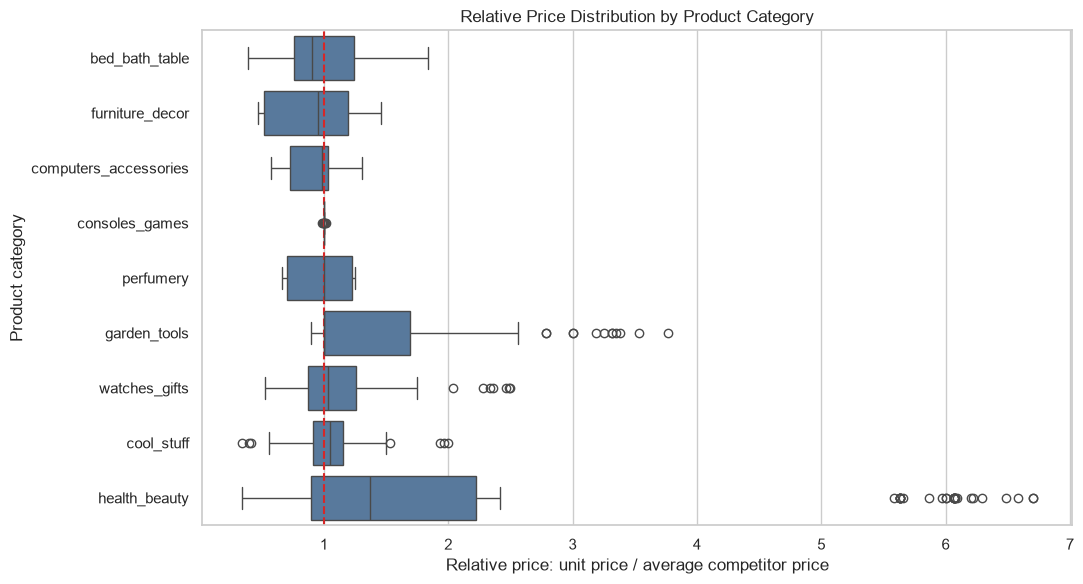

In [16]:
category_order = (
    df.groupby("product_category_name")["relative_price"]
    .median()
    .sort_values()
    .index
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=df,
    x="relative_price",
    y="product_category_name",
    order=category_order,
    color="#4C78A8",
    showfliers=True,
    ax=ax,
)
ax.axvline(1.0, color="#D62728", linestyle="--", linewidth=1.5)
ax.set_title("Relative Price Distribution by Product Category")
ax.set_xlabel("Relative price: unit price / average competitor price")
ax.set_ylabel("Product category")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_01_relative_price_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


### RQ2: Price and demand association


In [17]:
price_qty_summary = df[["qty", "unit_price", "avg_comp_price", "relative_price"]].corr(
    method="spearman"
)

display(price_qty_summary)
price_qty_summary.to_csv(TABLES_DIR / "table_09_price_quantity_correlations.csv")


,qty,unit_price,avg_comp_price,relative_price
qty,1.000,-0.083,-0.065,-0.034
unit_price,-0.083,1.000,0.578,0.648
avg_comp_price,-0.065,0.578,1.000,-0.102
relative_price,-0.034,0.648,-0.102,1.000


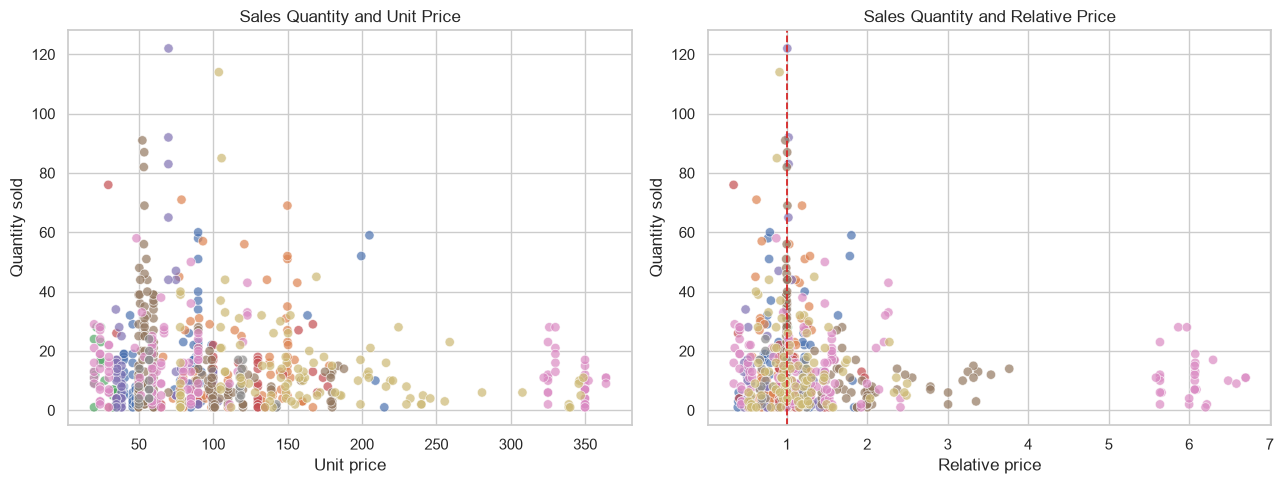

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df,
    x="unit_price",
    y="qty",
    hue="product_category_name",
    alpha=0.70,
    s=45,
    ax=axes[0],
    legend=False,
)
axes[0].set_title("Sales Quantity and Unit Price")
axes[0].set_xlabel("Unit price")
axes[0].set_ylabel("Quantity sold")

sns.scatterplot(
    data=df,
    x="relative_price",
    y="qty",
    hue="product_category_name",
    alpha=0.70,
    s=45,
    ax=axes[1],
    legend=False,
)
axes[1].axvline(1.0, color="#D62728", linestyle="--", linewidth=1.3)
axes[1].set_title("Sales Quantity and Relative Price")
axes[1].set_xlabel("Relative price")
axes[1].set_ylabel("Quantity sold")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_02_price_demand_relationships.png", dpi=300, bbox_inches="tight")
plt.show()


,month_year,total_qty,mean_qty,mean_unit_price,products
0,2017-01-01,9,4.500,207.445,2
1,2017-02-01,35,3.889,127.827,9
2,2017-03-01,101,7.769,122.587,13
3,2017-04-01,121,8.067,119.289,15
4,2017-05-01,222,11.100,104.786,20
5,2017-06-01,233,9.320,112.152,25
6,2017-07-01,403,12.212,105.112,33
7,2017-08-01,495,13.378,114.737,37
8,2017-09-01,450,12.500,112.336,36
9,2017-10-01,550,12.791,113.624,43


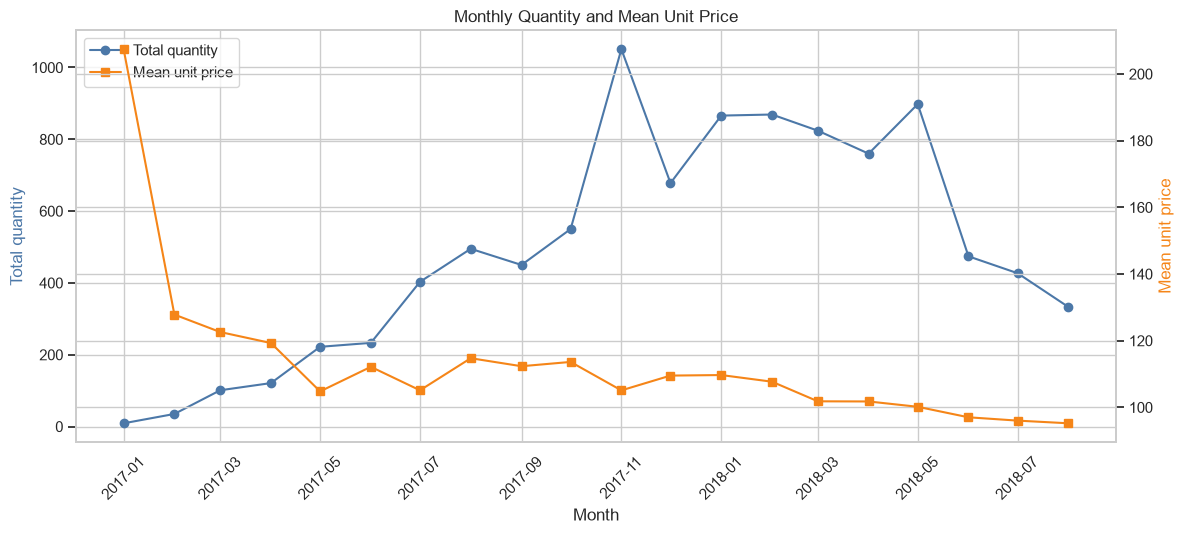

In [19]:
monthly_summary = (
    df.groupby("month_year")
    .agg(
        total_qty=("qty", "sum"),
        mean_qty=("qty", "mean"),
        mean_unit_price=("unit_price", "mean"),
        products=("product_id", "nunique"),
    )
    .reset_index()
)

display(monthly_summary)
monthly_summary.to_csv(TABLES_DIR / "table_10_monthly_summary.csv", index=False)

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax2 = ax1.twinx()

ax1.plot(
    monthly_summary["month_year"],
    monthly_summary["total_qty"],
    marker="o",
    color="#4C78A8",
    label="Total quantity",
)
ax2.plot(
    monthly_summary["month_year"],
    monthly_summary["mean_unit_price"],
    marker="s",
    color="#F58518",
    label="Mean unit price",
)

ax1.set_title("Monthly Quantity and Mean Unit Price")
ax1.set_xlabel("Month")
ax1.set_ylabel("Total quantity", color="#4C78A8")
ax2.set_ylabel("Mean unit price", color="#F58518")
ax1.tick_params(axis="x", rotation=45)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_03_monthly_quantity_and_price.png", dpi=300, bbox_inches="tight")
plt.show()


### RQ3: Predictive-modelling feasibility

This stage does not train the final models. It checks whether chronological partitions contain adequate product and category coverage and whether demand is strongly skewed.


In [20]:
train_end = pd.Timestamp("2018-02-01")
validation_end = pd.Timestamp("2018-05-01")

df["data_partition"] = np.select(
    [
        df["month_year"] <= train_end,
        (df["month_year"] > train_end) & (df["month_year"] <= validation_end),
        df["month_year"] > validation_end,
    ],
    ["Train", "Validation", "Test"],
    default="Unassigned",
)

partition_summary = (
    df.groupby("data_partition")
    .agg(
        rows=("product_id", "size"),
        products=("product_id", "nunique"),
        categories=("product_category_name", "nunique"),
        months=("month_year", "nunique"),
        first_month=("month_year", "min"),
        last_month=("month_year", "max"),
        mean_qty=("qty", "mean"),
    )
    .reindex(["Train", "Validation", "Test"])
    .reset_index()
)

display(partition_summary)
partition_summary.to_csv(TABLES_DIR / "table_11_time_partition_summary.csv", index=False)

partition_counts = df["data_partition"].value_counts()
for required_partition in ["Train", "Validation", "Test"]:
    if partition_counts.get(required_partition, 0) == 0:
        raise ValueError(
            f"{required_partition} partition is empty. Review date parsing and split boundaries."
        )

print("Verified: Train, Validation, and Test partitions are all non-empty.")


,data_partition,rows,products,categories,months,first_month,last_month,mean_qty
0,Train,418,52,9,14,2017-01-01,2018-02-01,14.553
1,Validation,138,50,9,3,2018-03-01,2018-05-01,17.986
2,Test,120,43,9,3,2018-06-01,2018-08-01,10.283


Verified: Train, Validation, and Test partitions are all non-empty.


In [21]:
partition_product_coverage = pd.crosstab(
    df["product_id"],
    df["data_partition"],
)

for partition in ["Train", "Validation", "Test"]:
    if partition not in partition_product_coverage.columns:
        partition_product_coverage[partition] = 0

partition_product_coverage["present_in_all_partitions"] = (
    partition_product_coverage[["Train", "Validation", "Test"]] > 0
).all(axis=1)

print(
    "Products represented in train, validation, and test:",
    int(partition_product_coverage["present_in_all_partitions"].sum()),
    "of",
    len(partition_product_coverage),
)

display(partition_product_coverage.head(10))
partition_product_coverage.to_csv(TABLES_DIR / "table_12_partition_product_coverage.csv")


Products represented in train, validation, and test: 43 of 52


data_partition,Test,Train,Validation,present_in_all_partitions
product_id,,,,
bed1,3,10,3,True
bed2,3,13,3,True
bed3,3,5,3,True
bed4,2,5,3,True
bed5,0,5,0,False
computers1,3,10,2,True
computers2,3,4,3,True
computers3,0,10,0,False
computers4,3,12,3,True


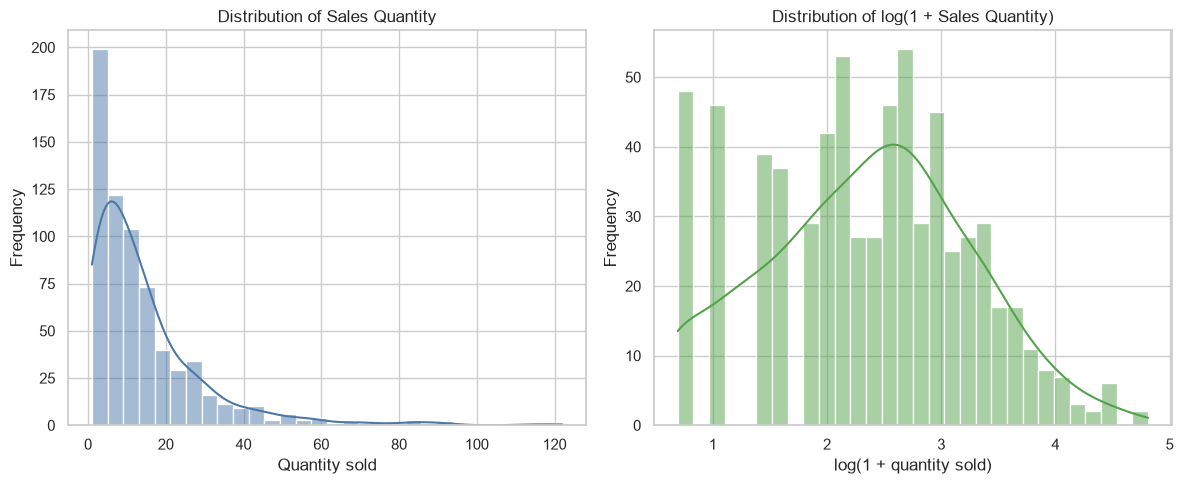

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["qty"], bins=30, kde=True, color="#4C78A8", ax=axes[0])
axes[0].set_title("Distribution of Sales Quantity")
axes[0].set_xlabel("Quantity sold")
axes[0].set_ylabel("Frequency")

sns.histplot(np.log1p(df["qty"]), bins=30, kde=True, color="#54A24B", ax=axes[1])
axes[1].set_title("Distribution of log(1 + Sales Quantity)")
axes[1].set_xlabel("log(1 + quantity sold)")
axes[1].set_ylabel("Frequency")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_04_quantity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


### RQ4: Category and competitive-price-position feasibility

Sparse category-position cells can make a factorial ANOVA unreliable. The cell-count table below determines whether the interaction should be confirmatory, reduced, or treated as exploratory.


In [23]:
rq4_cell_counts = pd.crosstab(
    df["product_category_name"],
    df["competitive_price_position"],
    dropna=False,
)

rq4_cell_counts["Total"] = rq4_cell_counts.sum(axis=1)
display(rq4_cell_counts)
rq4_cell_counts.to_csv(TABLES_DIR / "table_13_rq4_cell_counts.csv")

position_columns = [
    column for column in rq4_cell_counts.columns
    if column != "Total"
]

sparse_cells = int((rq4_cell_counts[position_columns] < 5).sum().sum())
print(f"Cells with fewer than 5 observations: {sparse_cells}")

if sparse_cells > 0:
    print(
        "RQ4 should be interpreted cautiously. Consider an interaction regression, "
        "category consolidation only if conceptually defensible, or exploratory reporting."
    )


competitive_price_position,Below competitor average,Near competitor average,Above competitor average,Total
product_category_name,,,,
bed_bath_table,31,3,27,61
computers_accessories,31,24,14,69
consoles_games,0,22,0,22
cool_stuff,23,5,29,57
furniture_decor,24,7,17,48
garden_tools,2,103,55,160
health_beauty,36,11,83,130
perfumery,11,4,11,26
watches_gifts,35,21,47,103


Cells with fewer than 5 observations: 5
RQ4 should be interpreted cautiously. Consider an interaction regression, category consolidation only if conceptually defensible, or exploratory reporting.


In [24]:
position_summary = (
    df.groupby(
        ["product_category_name", "competitive_price_position"],
        observed=False,
    )
    .agg(
        observations=("qty", "size"),
        mean_qty=("qty", "mean"),
        median_qty=("qty", "median"),
        mean_unit_price=("unit_price", "mean"),
    )
    .reset_index()
)

display(position_summary)
position_summary.to_csv(TABLES_DIR / "table_14_rq4_position_summary.csv", index=False)


,product_category_name,competitive_price_position,observations,mean_qty,median_qty,mean_unit_price
0,bed_bath_table,Below competitor average,31,16.226,11.000,51.360
1,bed_bath_table,Near competitor average,3,19.333,22.000,89.900
2,bed_bath_table,Above competitor average,27,17.222,14.000,108.687
3,computers_accessories,Below competitor average,31,14.323,7.000,90.311
4,computers_accessories,Near competitor average,24,11.958,9.500,140.433
5,computers_accessories,Above competitor average,14,31.143,29.000,148.161
6,consoles_games,Below competitor average,0,NaN,NaN,NaN
7,consoles_games,Near competitor average,22,10.864,9.000,27.034
8,consoles_games,Above competitor average,0,NaN,NaN,NaN
9,cool_stuff,Below competitor average,23,12.391,9.000,88.209


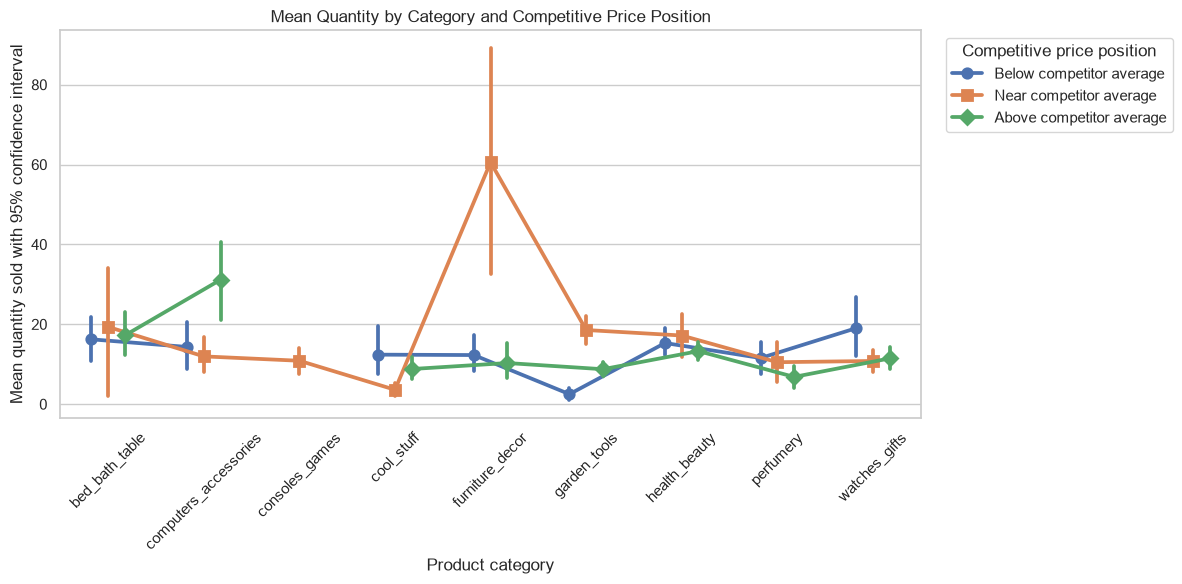

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.pointplot(
    data=df,
    x="product_category_name",
    y="qty",
    hue="competitive_price_position",
    errorbar=("ci", 95),
    dodge=0.35,
    markers=["o", "s", "D"],
    ax=ax,
)
ax.set_title("Mean Quantity by Category and Competitive Price Position")
ax.set_xlabel("Product category")
ax.set_ylabel("Mean quantity sold with 95% confidence interval")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Competitive price position", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_05_category_position_quantity.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Outlier review without automatic deletion

Outliers are identified using the interquartile-range rule for documentation. They are not automatically removed because high demand and high prices may be real business observations. Modelling decisions will compare robust transformations or models where appropriate.


In [26]:
def iqr_outlier_summary(data, columns):
    records = []
    for column in columns:
        series = data[column].dropna()
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        flagged = ((series < lower) | (series > upper)).sum()
        records.append({
            "Variable": column,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Flagged_Rows": int(flagged),
            "Flagged_Percent": round(100 * flagged / len(series), 2),
        })
    return pd.DataFrame(records)

outlier_columns = [
    column for column in [
        "qty",
        "unit_price",
        "freight_price",
        "relative_price",
        "customers",
    ]
    if column in df.columns
]

outlier_summary = iqr_outlier_summary(df, outlier_columns)
display(outlier_summary)
outlier_summary.to_csv(TABLES_DIR / "table_15_outlier_review.csv", index=False)


,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Flagged_Rows,Flagged_Percent
0,qty,4.000,18.000,14.000,-17.000,39.000,42,6.210
1,unit_price,53.900,129.990,76.090,-60.235,244.125,45,6.660
2,freight_price,14.762,22.714,7.952,2.834,34.641,76,11.240
3,relative_price,0.909,1.300,0.391,0.323,1.887,81,11.980
4,customers,34.000,116.000,82.000,-89.000,239.000,18,2.660


## 9. Leakage audit and modelling eligibility

The table below records whether fields are initially eligible for demand modelling. Final feature selection will occur in the modelling notebook and will be fitted using training data only.


In [27]:
leakage_audit_records = [
    {
        "Variable": "qty",
        "Initial_Status": "Target only",
        "Reason": "Demand outcome; cannot be used as its own predictor.",
    },
    {
        "Variable": "total_price",
        "Initial_Status": "Exclude",
        "Reason": "Contains current quantity and price information; direct target leakage risk.",
    },
    {
        "Variable": "calculated_revenue",
        "Initial_Status": "Exclude",
        "Reason": "Defined as current qty multiplied by unit_price; direct target leakage.",
    },
    {
        "Variable": "lag_price",
        "Initial_Status": "Exclude pending validation",
        "Reason": "Supplied feature construction is not fully documented and differs in some rows.",
    },
    {
        "Variable": "recalculated_lag_price",
        "Initial_Status": "Candidate",
        "Reason": "Transparent previous observed price created chronologically by product.",
    },
    {
        "Variable": "previous_qty",
        "Initial_Status": "Candidate",
        "Reason": "Previous observed demand created with shift(1); unavailable for first product record.",
    },
    {
        "Variable": "unit_price",
        "Initial_Status": "Candidate and decision variable",
        "Reason": "Price is required to estimate the price-demand association and simulate revenue.",
    },
    {
        "Variable": "month_year",
        "Initial_Status": "Do not use directly",
        "Reason": "Use derived calendar or ordered-time features instead of the raw timestamp.",
    },
]

leakage_audit = pd.DataFrame(leakage_audit_records)
display(leakage_audit)
leakage_audit.to_csv(TABLES_DIR / "table_16_leakage_audit.csv", index=False)


,Variable,Initial_Status,Reason
0,qty,Target only,Demand outcome; cannot be used as its own pred...
1,total_price,Exclude,Contains current quantity and price informatio...
2,calculated_revenue,Exclude,Defined as current qty multiplied by unit_pric...
3,lag_price,Exclude pending validation,Supplied feature construction is not fully doc...
4,recalculated_lag_price,Candidate,Transparent previous observed price created ch...
5,previous_qty,Candidate,Previous observed demand created with shift(1)...
6,unit_price,Candidate and decision variable,Price is required to estimate the price-demand...
7,month_year,Do not use directly,Use derived calendar or ordered-time features ...


## 10. Export the analysis-ready dataset

The exported dataset retains audit fields for transparency. Modelling pipelines must explicitly exclude target-derived fields and fit preprocessing only on training data.


In [28]:
OUTPUT_DATA_PATH = PROCESSED_DIR / "retail_price_analysis_ready.csv"
df.to_csv(OUTPUT_DATA_PATH, index=False)

metadata = {
    "source_file": str(DATA_PATH),
    "output_file": str(OUTPUT_DATA_PATH),
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "observation_unit": "product-month",
    "products": int(df["product_id"].nunique()),
    "categories": int(df["product_category_name"].nunique()),
    "months": int(df["month_year"].nunique()),
    "date_min": df["month_year"].min().strftime("%Y-%m-%d"),
    "date_max": df["month_year"].max().strftime("%Y-%m-%d"),
    "random_state": RANDOM_STATE,
    "target_for_demand_modelling": "qty",
    "pricing_decision_variable": "unit_price",
    "optimization_objective": "simulated predicted revenue, not profit",
}

with open(PROCESSED_DIR / "retail_price_analysis_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"Saved analysis-ready data: {OUTPUT_DATA_PATH}")
print(f"Saved figures: {FIGURES_DIR}")
print(f"Saved tables: {TABLES_DIR}")
print(f"Output shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")


Saved analysis-ready data: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\processed\retail_price_analysis_ready.csv
Saved figures: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\reports\figures
Saved tables: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\reports\tables
Output shape: 676 rows x 52 columns


## 11. Automated completion checklist


In [29]:
expected_outputs = [
    OUTPUT_DATA_PATH,
    PROCESSED_DIR / "retail_price_analysis_metadata.json",
    TABLES_DIR / "table_01_dataset_structure.csv",
    TABLES_DIR / "table_06_category_coverage.csv",
    TABLES_DIR / "table_11_time_partition_summary.csv",
    TABLES_DIR / "table_13_rq4_cell_counts.csv",
    TABLES_DIR / "table_16_leakage_audit.csv",
    FIGURES_DIR / "figure_01_relative_price_by_category.png",
    FIGURES_DIR / "figure_02_price_demand_relationships.png",
    FIGURES_DIR / "figure_03_monthly_quantity_and_price.png",
    FIGURES_DIR / "figure_04_quantity_distribution.png",
    FIGURES_DIR / "figure_05_category_position_quantity.png",
]

completion_check = pd.DataFrame({
    "Output": [str(path.relative_to(PROJECT_ROOT)) for path in expected_outputs],
    "Exists": [path.exists() for path in expected_outputs],
})

display(completion_check)

if completion_check["Exists"].all():
    print("Notebook 02 completed successfully. All expected outputs were created.")
else:
    print("Some expected outputs are missing. Review the cells above for errors.")


,Output,Exists
0,data\processed\retail_price_analysis_ready.csv,True
1,data\processed\retail_price_analysis_metadata....,True
2,reports\tables\table_01_dataset_structure.csv,True
3,reports\tables\table_06_category_coverage.csv,True
4,reports\tables\table_11_time_partition_summary...,True
5,reports\tables\table_13_rq4_cell_counts.csv,True
6,reports\tables\table_16_leakage_audit.csv,True
7,reports\figures\figure_01_relative_price_by_ca...,True
8,reports\figures\figure_02_price_demand_relatio...,True
9,reports\figures\figure_03_monthly_quantity_and...,True


Notebook 02 completed successfully. All expected outputs were created.


## 12. Interpretation notes for the interim report

Complete these notes only after reviewing the executed outputs:

1. **Dataset and observation unit:** Report the verified number of product-month records, products, categories, and months.
2. **Data completeness:** Report missingness, duplicate results, business-rule flags, and why observations were retained or excluded.
3. **RQ1:** Describe category differences in relative price without yet claiming statistical significance.
4. **RQ2:** Describe the direction, strength, and nonlinearity of price-demand associations while avoiding causal language.
5. **RQ3:** Report whether chronological partitions retain adequate product and category coverage and whether the target distribution requires transformation or robust modelling.
6. **RQ4:** Report sparse category-position cells and label the interaction analysis exploratory if assumptions are weak.
7. **Leakage:** Explain why `total_price` is excluded and why supplied `lag_price` is treated cautiously.
8. **Limitations:** State that the public dataset has limited organizational provenance and repeated observations of the same products.

### Next notebook

After reviewing and saving all outputs, proceed to:

`03_statistical_analysis_and_sample_size.ipynb`

That notebook will perform reproducible sample-size/sensitivity calculations and the formal statistical analysis for RQ1, RQ2, and RQ4.
